# CVRIE — Unsupervised Learning

## 1. Exploration du dataset (EDA)

Objectif : comprendre la structure réelle de `Student_Dataset.csv` avant tout traitement

### Tentative 1 (échec)
pd.read_csv direct avec header=None → ParserError : nombre de colonnes incohérent selon les lignes.

### Tentative 2
Lecture manuelle avec le module csv pour assigner correctement chaque valeur.

In [1]:
# on ouvre le fichier brut, sans passer par pandas
with open("data/Student_Dataset.csv") as f:
    lignes = f.readlines()

# on regarde les 5 premières lignes telles quelles
for ligne in lignes[:5]:
    print(ligne)

ï»¿1,On uneven paths the heel feels wobbly sideâ€‘toâ€‘side. Slanted pavements bring a quick aching shift under the ankle when I step.

2,0x000000,"The feverish feeling eased, but Iâ€™m now breathing faster with a dry, exhausting cough. I get lightâ€‘headed after climbing stairs and feel like I canâ€™t fill my lungs completely."

3,0x000000,"While working in the garden, I touched a metal grill that had been on the stove. My left forearm has a burning itch and a faint scar."

4,A short sprint brought on a twinge in the middle of the back of my thigh. Itâ€™s tender along a band and stiffens if I sit too long.

5,0x000000,"I accidentally left my hand on a hot mug for a minute. It now feels very tender, and there's a small blister."



In [2]:
import pandas as pd
import csv

# on va stocker chaque valeur dans des listes séparées
ids = []
couleurs = []
textes = []

with open("data/Student_Dataset.csv", encoding="utf-8-sig") as f:
    lecteur = csv.reader(f)
    for ligne in lecteur:
        # si la ligne a 3 champs, elle a la couleur cachée
        if len(ligne) == 3:
            id_, couleur, texte = ligne
        # sinon elle n'a que l'id et le texte
        elif len(ligne) == 2:
            id_, texte = ligne
            couleur = None
        else:
            print("ligne inattendue :", ligne)
            continue
        ids.append(id_)
        couleurs.append(couleur)
        textes.append(texte)

# on reconstruit un DataFrame propre à partir de nos listes
df = pd.DataFrame({"id": ids, "couleur": couleurs, "texte": textes})

print(df.shape)
print(df["couleur"].isnull().sum())
df.head(10)

(1011, 3)
397


,id,couleur,texte
0,1,NaN,On uneven paths the heel feels wobbly side‑to‑...
1,2,0x000000,"The feverish feeling eased, but I’m now breath..."
2,3,0x000000,"While working in the garden, I touched a metal..."
3,4,NaN,A short sprint brought on a twinge in the midd...
4,5,0x000000,I accidentally left my hand on a hot mug for a...
5,6,NaN,A sudden twist while reaching for a bag made o...
6,7,0x000000,"During a birthday party, a hot beverage was kn..."
7,8,NaN,I noticed a rash on my forearms after handling...
8,9,0x000000,"Since I lost 20 pounds, my headaches have less..."
9,10,0x000000,The rash on my face and jaw is a classic hives...


In [3]:
# on vérifie s'il y a des textes manquants 
print(df["texte"].isnull().sum())
# on regarde les valeurs uniques de couleur pour confirmer que c'est bien un placeholder unique
print(df["couleur"].unique())
# verification  s'il y a des id en double
print(df["id"].duplicated().sum())

0
<StringArray>
[nan, '0x000000']
Length: 2, dtype: str
0


## 2. Preprocessing du texte

### Hypothèse
Un nettoyage simple (minuscules + suppression de la ponctuation) suffit pour une première vectorisation. On testera plus tard si enlever les stopwords améliore les résultats.

In [4]:
import re

def nettoyer_texte(texte):
    texte = texte.lower()  # tout en minuscules
    texte = re.sub(r"[-‑–—]", " ", texte)  # on remplace les tirets (classiques et typographiques) par un espace
    texte = re.sub(r"[^\w\s]", "", texte)  # on enlève le reste de la ponctuation
    texte = re.sub(r"\s+", " ", texte).strip()  # on enlève les espaces en trop
    return texte

# on réapplique la fonction corrigée
df["texte_clean"] = df["texte"].apply(nettoyer_texte)

# on revérifie le même exp
print("AVANT :", df["texte"].iloc[0])
print("APRES :", df["texte_clean"].iloc[0])

AVANT : On uneven paths the heel feels wobbly side‑to‑side. Slanted pavements bring a quick aching shift under the ankle when I step.
APRES : on uneven paths the heel feels wobbly side to side slanted pavements bring a quick aching shift under the ankle when i step


### Correction
Le premier nettoyage supprimait les tirets typographiques (‑) au lieu de les remplacer par un espace, ce qui collait les mots ensemble (ex: "side-to-side" → "sidetoside"). Corrigé en remplaçant les tirets par un espace avant de retirer le reste de la ponctuation.

In [5]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# on vérifie si "side" fait partie de la liste de stopwords
print("side" in ENGLISH_STOP_WORDS)

True


### Vérification de la liste de stopwords
La liste standard de scikit-learn supprime des mots de négation ("no", "not") et des mots de position ("side", "back", "front", "top", "bottom") qui sont pertinents pour décrire des symptômes physiques. On les exclut de la suppression.

In [6]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# on garde les négations et les mots de position/direction, importants pour décrire des symptômes
mots_a_garder = {"no", "not", "never", "none", "nothing", "side", "back", "front", "top", "bottom"}
stopwords_medical = ENGLISH_STOP_WORDS - mots_a_garder

def enlever_stopwords(texte):
    mots = texte.split()  # on découpe la phrase en mots
    mots_filtres = [mot for mot in mots if mot not in stopwords_medical]
    return " ".join(mots_filtres)

# on applique sur le texte déjà nettoyé (minuscules + sans ponctuation)
df["texte_clean"] = df["texte_clean"].apply(enlever_stopwords)

print("APRES (sans stopwords) :", df["texte_clean"].iloc[0])

APRES (sans stopwords) : uneven paths heel feels wobbly side side slanted pavements bring quick aching shift ankle step


In [7]:
# on affiche la représentation brute du premier id pour voir s'il y a un caractère caché
print(repr(df["id"].iloc[0]))

'1'


## 3. Vectorisation du texte (TF-IDF)

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

# on transforme chaque témoignage en vecteur de nombres (TF-IDF)
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df["texte_clean"])

# on regarde la taille du résultat : (nombre de témoignages, nombre de mots uniques)
print(X.shape)

(1011, 2154)


## 4. Premier clustering (baseline)

### Hypothèse
On teste KMeans avec un nombre de clusters arbitraire (k=5) pour une première baseline, sans prétendre que c'est le bon nombre. On comparera différentes valeurs plus tard.

In [9]:
from sklearn.cluster import KMeans

# on teste une première baseline avec 5 clusters (valeur arbitraire pour commencer)
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X)
# on ajoute le résultat dans le dataframe pour pouvoir l'analyser
df["cluster"] = clusters

# on regarde combien de témoignages sont tombés dans chaque cluster
print(df["cluster"].value_counts())

cluster
1    303
4    299
0    208
3    119
2     82
Name: count, dtype: int64


### Vérification rapide : les clusters ont-ils du sens ?

In [10]:
# on regarde 3 exemples de témoignages pour chaque cluster
for c in sorted(df["cluster"].unique()):
    print(f"--- Cluster {c} ---")
    exemples = df[df["cluster"] == c]["texte"].head(3)
    for texte in exemples:
        print("-", texte)
    print()

--- Cluster 0 ---
- While working in the garden, I touched a metal grill that had been on the stove. My left forearm has a burning itch and a faint scar.
- I accidentally left my hand on a hot mug for a minute. It now feels very tender, and there's a small blister.
- During a birthday party, a hot beverage was knocked onto my back. The area is red, tender, and a small blister is visible on my shoulder.

--- Cluster 1 ---
- The feverish feeling eased, but I’m now breathing faster with a dry, exhausting cough. I get light‑headed after climbing stairs and feel like I can’t fill my lungs completely.
- Since I lost 20 pounds, my headaches have lessened, but I still feel lightheaded when I stand up. I believe my diet is the culprit. I haven't checked my blood pressure.
- I have an increased thirst level and I’m going to the bathroom more than usual. I’ve been losing weight without effort. The doctor suspected a blood sugar disorder.

--- Cluster 2 ---
- I woke up with a runny nose and a sore

## 5. Comparaison de plusieurs valeurs de k (silhouette score)

### Hypothèse
On teste plusieurs valeurs de k (2 à 10) et on compare leur silhouette score pour choisir une valeur justifiée plutôt qu'arbitraire.

k=2 -> silhouette score = 0.007
k=3 -> silhouette score = 0.011
k=4 -> silhouette score = 0.011
k=5 -> silhouette score = 0.014
k=6 -> silhouette score = 0.014
k=7 -> silhouette score = 0.016
k=8 -> silhouette score = 0.016
k=9 -> silhouette score = 0.018
k=10 -> silhouette score = 0.017


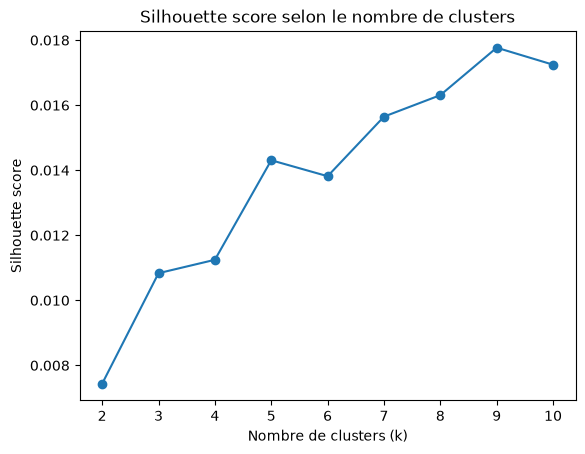

In [11]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

scores = []
k_values = range(2, 11)

# on teste chaque valeur de k et on calcule son silhouette score
for k in k_values:
    kmeans_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans_test.fit_predict(X)
    score = silhouette_score(X, labels)
    scores.append(score)
    print(f"k={k} -> silhouette score = {score:.3f}")

# on trace un graphique pour voir facilement quel k donne le meilleur score
plt.plot(k_values, scores, marker="o")
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score selon le nombre de clusters")
plt.show()

### Résultat : silhouette scores très faibles
Tous les scores restent très bas (0.007 à 0.018), loin d'un score jugé correct (>0.25). Hypothèse : l'espace TF-IDF a trop de dimensions (2154) par rapport au nombre de témoignages (1011), ce qui peut fausser un score basé sur la distance euclidienne (curse of dimensionality). Nouvelle expérience : réduire les dimensions avant de reclusteriser

In [12]:
from sklearn.decomposition import TruncatedSVD

# on réduit à 100 dimensions pour voir si ça aide le clustering à mieux séparer les groupes
svd = TruncatedSVD(n_components=100, random_state=42)
X_reduced = svd.fit_transform(X)

print(X_reduced.shape)

(1011, 100)


### Nouvelle expérience : silhouette score sur l'espace réduit (SVD, 100 dimensions)

k=2 -> silhouette score (SVD) = 0.070
k=3 -> silhouette score (SVD) = 0.036
k=4 -> silhouette score (SVD) = 0.036
k=5 -> silhouette score (SVD) = 0.034
k=6 -> silhouette score (SVD) = 0.038
k=7 -> silhouette score (SVD) = 0.036
k=8 -> silhouette score (SVD) = 0.045
k=9 -> silhouette score (SVD) = 0.049
k=10 -> silhouette score (SVD) = 0.046


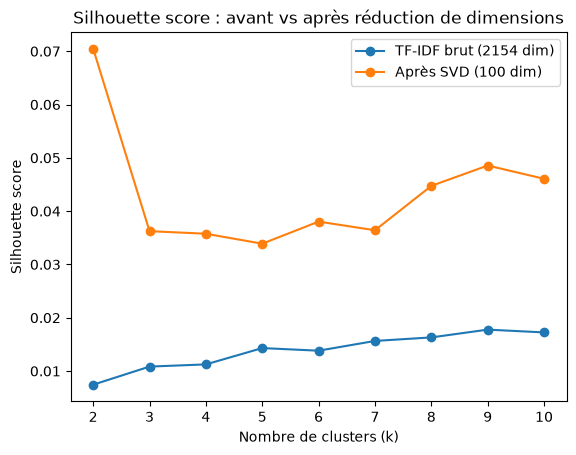

In [13]:
scores_svd = []

# on refait la même comparaison de k, mais sur les données réduites (X_reduced)
for k in k_values:
    kmeans_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans_test.fit_predict(X_reduced)
    score = silhouette_score(X_reduced, labels)
    scores_svd.append(score)
    print(f"k={k} -> silhouette score (SVD) = {score:.3f}")

# on compare visuellement les deux courbes (avant/après réduction)
plt.plot(k_values, scores, marker="o", label="TF-IDF brut (2154 dim)")
plt.plot(k_values, scores_svd, marker="o", label="Après SVD (100 dim)")
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score : avant vs après réduction de dimensions")
plt.legend()
plt.show()

### Investigation du k=2 (score le plus élevé)

In [14]:
# on relance KMeans avec k=2 sur les données réduites (SVD)
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)
df["cluster_k2"] = kmeans_2.fit_predict(X_reduced)

print(df["cluster_k2"].value_counts())

# on regarde quelques exemples de chaque groupe
for c in sorted(df["cluster_k2"].unique()):
    print(f"--- Groupe {c} ---")
    for texte in df[df["cluster_k2"] == c]["texte"].head(4):
        print("-", texte)
    print()

cluster_k2
0    876
1    135
Name: count, dtype: int64
--- Groupe 0 ---
- On uneven paths the heel feels wobbly side‑to‑side. Slanted pavements bring a quick aching shift under the ankle when I step.
- The feverish feeling eased, but I’m now breathing faster with a dry, exhausting cough. I get light‑headed after climbing stairs and feel like I can’t fill my lungs completely.
- While working in the garden, I touched a metal grill that had been on the stove. My left forearm has a burning itch and a faint scar.
- A short sprint brought on a twinge in the middle of the back of my thigh. It’s tender along a band and stiffens if I sit too long.

--- Groupe 1 ---
- I woke up with a runny nose and a sore throat, but I thought it was just a bad cold. The congestion hasn't cleared even after I tried decongestants. I have been feeling slightly feverish and tired.
- Since last week, my right ear has been aching and I noticed a slight fluid drainage. I feel a buzzing sound when I move my head. The 

### Conclusion sur k=2
Hypothèse "localisé vs systémique" réfutée. Le Groupe 1 (135) est en réalité un thème rhume/grippe très spécifique, pas un groupe "systémique" large. Le Groupe 0 (876) reste hétérogène. Le score élevé de k=2 vient d'un sous-groupe à vocabulaire répétitif isolé du reste, pas d'une vraie séparation en 2 thèmes équilibrés. On garde cette piste en tête mais on ne retient pas k=2 comme solution finale.

### Investigation du k=9 (sur données réduites)

In [15]:
kmeans_9 = KMeans(n_clusters=9, random_state=42, n_init=10)
df["cluster_k9"] = kmeans_9.fit_predict(X_reduced)

print(df["cluster_k9"].value_counts())

for c in sorted(df["cluster_k9"].unique()):
    print(f"--- Groupe {c} ---")
    for texte in df[df["cluster_k9"] == c]["texte"].head(3):
        print("-", texte)
    print()

cluster_k9
7    349
6    163
4    146
1     77
2     77
3     58
8     55
5     50
0     36
Name: count, dtype: int64
--- Groupe 0 ---
- There’s a small sore area on the top of my foot that flares when I push off while walking. Tight shoes make it throb and I limp by the evening.
- I rolled my ankle stepping off a curb. There’s a tender point along the outside bone above the ankle and it’s hard to put weight without a sharp twinge.
- Landing with the foot turned left a deep ache on the outer back of the ankle. Pushing the foot outward or downhill walking makes it spike.

--- Groupe 1 ---
- I noticed a rash on my forearms after handling a new brand of sunscreen. The spots are itchy and raised. I didn’t realize it could be an allergic reaction until it started spreading. I’ve stopped using the product.
- The rash on my face and jaw is a classic hives appearance. It’s raised, itchy, and pink. I feel a tingling sensation. I think it might be food‑related.
- After eating lunch, I noticed a 

### Résultat k=9 (données réduites)
6 clusters sur 9 sont thématiquement cohérents (pied/cheville, allergies, rhume, oreille/grippe, brûlures, migraines). Le cluster 7 (349, le plus gros) reste un fourre-tout imparfait (contient une brûlure mal classée). Ce k=9 est pour l'instant notre meilleure baseline en termes de cohérence observée, malgré un score silhouette encore modeste (0.049).

## 6. Visualisation des clusters (k=9)

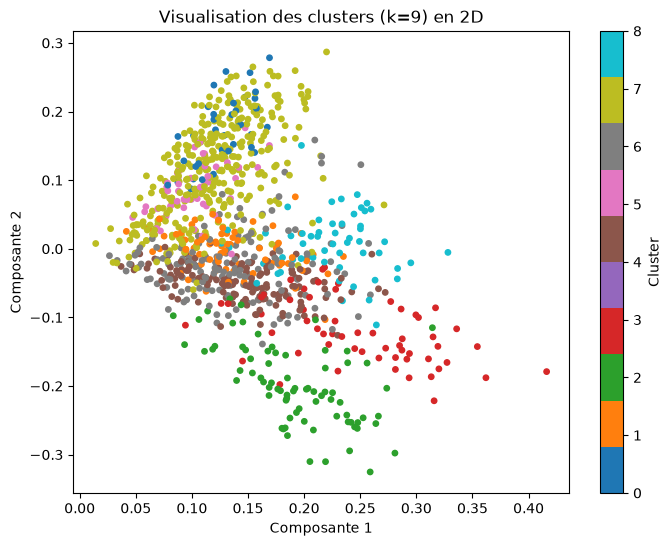

In [16]:
# on réduit à 2 dimensions uniquement pour pouvoir visualiser (pas pour le clustering)
svd_2d = TruncatedSVD(n_components=2, random_state=42)
X_2d = svd_2d.fit_transform(X_reduced)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=df["cluster_k9"], cmap="tab10", s=15)
plt.xlabel("Composante 1")
plt.ylabel("Composante 2")
plt.title("Visualisation des clusters (k=9) en 2D")
plt.colorbar(scatter, label="Cluster")
plt.show()

### Essai avec t-SNE (autre méthode de visualisation)

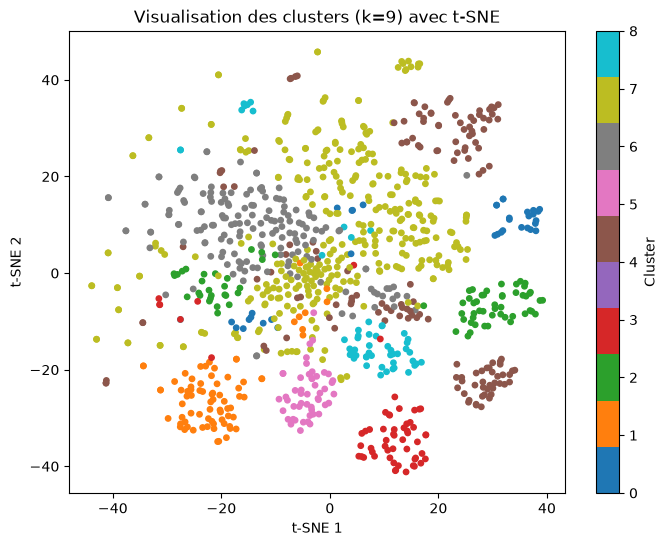

In [17]:
from sklearn.manifold import TSNE

# t-SNE est souvent meilleur que SVD pour visualiser des clusters en 2D
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_reduced)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=df["cluster_k9"], cmap="tab10", s=15)
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Visualisation des clusters (k=9) avec t-SNE")
plt.colorbar(scatter, label="Cluster")
plt.show()

### Conclusion visualisation
t-SNE sépare beaucoup mieux les clusters que la projection SVD-2D. 7 clusters sur 9 sont visuellement distincts et correspondent aux thèmes identifiés manuellement. Les clusters 6 et 7 restent mélangés, cohérent avec leur manque de cohérence déjà observé dans les textes. Convergence de 3 signaux (silhouette, lecture manuelle, visualisation) pour valider 7/9 clusters.

## 7. Validation avec la couleur cachée (préliminaire)

### Hypothèse
La couleur actuelle (0x000000 / NaN) est un placeholder technique, pas la vraie information médicale (révélée plus tard). On vérifie ici, à titre préliminaire, si un lien existe déjà avec nos clusters

### Résultat
Le pourcentage de couleur manquante varie de 18.0% (cluster 5, brûlures) à 60.3% (cluster 3, oreille/grippe), autour d'une moyenne globale de 39.3%. Ce n'est pas uniforme

### Interprétation
Cet écart pourrait indiquer un lien entre thème et masquage, mais plusieurs clusters ont peu d'échantillons (36 à 58 témoignages), ce qui rend une partie de cette variation potentiellement due au hasard statistique plutôt qu'à un vrai signal. Conclusion à confirmer uniquement après révélation de la vraie couleur

In [18]:
import pandas as pd

# on regarde, pour chaque cluster, la proportion de couleur manquante (NaN)
crosstab = pd.crosstab(df["cluster_k9"], df["couleur"].isnull())
crosstab.columns = ["couleur présente", "couleur manquante"]

# on ajoute le pourcentage de couleur manquante par cluster pour comparer facilement
crosstab["% manquante"] = (crosstab["couleur manquante"] / (crosstab["couleur présente"] + crosstab["couleur manquante"]) * 100).round(1)

print(crosstab)

            couleur présente  couleur manquante  % manquante
cluster_k9                                                  
0                         15                 21         58.3
1                         51                 26         33.8
2                         52                 25         32.5
3                         23                 35         60.3
4                         74                 72         49.3
5                         41                  9         18.0
6                        108                 55         33.7
7                        211                138         39.5
8                         39                 16         29.1


## 8. Limites

- Le clustering repose sur TF-IDF, une méthode purement basée sur le vocabulaire (pas de compréhension du sens) — deux témoignages proches en sens mais avec des mots différents peuvent être mal regroupés
- Les scores silhouette restent modestes (0.03-0.07 après réduction de dimensions), donc les clusters ne sont pas parfaitement séparés mathématiquement, même si la lecture manuelle et la visualisation t-SNE confirment une cohérence pour 7 clusters sur 9
- Le cluster 7 (le plus gros, 349 témoignages) reste un fourre-tout imparfait
- La colonne couleur actuelle est un placeholder technique — la validation finale ne pourra se faire qu'après sa révélation par le professeur. Notre check préliminaire montre une variation intéressante (18% à 60% de couleur manquante selon le cluster) mais peu fiable statistiquement pour les petits clusters (36-58 échantillons)
- Le nombre de clusters (k=9) a été choisi par comparaison de scores et lecture manuelle, pas par une méthode purement automatique

## 9. Conclusion

Notre démarche a suivi un cycle hypothèse → expérience → résultat → analyse à chaque étape : nettoyage du texte (avec correction de deux bugs réels : tirets typographiques et BOM), retrait des stopwords (avec protection des négations et mots de position, pertinents en contexte médical), vectorisation TF-IDF, puis clustering KMeans. Une première baseline (k=5 arbitraire) a donné des résultats encourageants à la lecture manuelle. La comparaison de plusieurs valeurs de k via le silhouette score a révélé des scores globalement faibles sur le TF-IDF brut, attribués à la haute dimensionnalité (2154 mots pour 1011 témoignages). La réduction de dimensions (SVD) a amélioré les scores. Le test de k=2 a révélé une hypothèse erronée (localisé vs systémique), corrigée après lecture des vrais textes. Le passage à k=9 a produit 7 clusters thématiquement cohérents confirmés par 3 signaux indépendants : score silhouette, lecture manuelle, et visualisation t-SNE. Un check préliminaire sur la couleur masquée montre une variation notable mais non conclusive en l'état

## 10. Insights

- Un score mathématique de clustering et la cohérence médicale perçue sont deux choses différentes qu'il faut croiser, pas confondre.
- Documenter les échecs (BOM, tirets, hypothèse k=2 réfutée) a été aussi utile que les succès pour comprendre le dataset
- La visualisation choisie change complètement la lecture qu'on peut faire d'un même clustering (SVD vs t-SNE)
- Un résultat statistique surprenant (variation de couleur manquante par cluster) doit être signalé, mais pas sur-interprété quand la taille d'échantillon est petite